# Walkthrough: `03_build_macro_tables.py` (Macroeconomic Series & PRA LGD Discount Rates)

### Simple Summary
**This script loads public US macroeconomic time series (Federal Funds Rate, Unemployment Rate, and FHFA House Price Index) into DuckDB, computes 1-month and 12-month changes by exact calendar date, derives PRA-aligned LGD discount rates (long-run at `EFFR + 5%`, downturn floored at `9%`), and verifies all 6 integrity checks.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook runs the macro pipeline strictly **in memory** from the saved CSVs in `00_data/raw/macro/` and compares against `mortgages_sample.duckdb` (`READ_ONLY`) without altering any database on disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Load 3 Macro CSVs</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">EFFR, UNRATE &amp; FHFA HPI</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. Date-Exact Deltas</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">1m &amp; 12m shifts (no gap fill)</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. LGD Discount Rates</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">EFFR + 5% &amp; 9% downturn floor</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. 6 Checks &amp; Chart</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Rate floor regime visual</text>
</svg>
</div>

---
### 1. Checking Raw Macro CSV Headers & Starting an In-Memory Session
Rather than downloading silently on every run, `03_build_macro_tables.py` reads the local CSV files under `00_data/raw/macro/` (`fedfunds.csv`, `unrate.csv`, `hpi_master.csv`) and checks their headers first. Here we inspect those local files and load them into an isolated in-memory DuckDB session.

In [1]:
# Load system, database, dataframe, and plotting modules
# Import pathlib, sys, duckdb, pandas, and matplotlib for macro ingestion verification
import sys
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Locate residential_mortgage/ root and attach 00_data/scripts so we can reuse build_macro_tables
# Walk upward to residential_mortgage/, insert scripts/ on sys.path, and set macro_dir
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

SCRIPTS_DIR = PACKAGE_ROOT / "00_data/scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import importlib
macro_mod = importlib.import_module("03_build_macro_tables")
MACRO_DIR = PACKAGE_ROOT / "00_data/raw/macro"

# Verify that all 3 macro CSV headers match expected signatures before parsing
# Call macro_mod.first_line_ok on each CSV and report file size in KB
pd.DataFrame([{
    "File": fname,
    "Header Valid": macro_mod.first_line_ok(MACRO_DIR / fname, fname),
    "Size (KB)": round((MACRO_DIR / fname).stat().st_size / 1024, 1),
} for fname in macro_mod.EXPECTED_HEADERS])

,File,Header Valid,Size (KB)
0,fedfunds.csv,True,13.6
1,unrate.csv,True,13.9
2,hpi_master.csv,True,16755.1


All three raw macro files pass header validation. Next, we run the exact `build_macro_tables()` builder inside a fresh `:memory:` DuckDB database so we can inspect the generated tables without touching disk.

---
### 2. Building the Macro Tables & PRA LGD Discount Rates in Memory
Calling `macro_mod.build_macro_tables(con, MACRO_DIR)` inside `:memory:` builds the complete calendar (`macro_monthly_table`, `macro_state_hpi_table`, `macro_economic_mart`, and `macro_sources_table`), leaves missing unemployment months un-filled (`unemployment_missing = True`), and calculates two regulatory LGD discount rates:

$$\text{Long-Run Rate} = \text{EFFR} + 5.0\% \qquad \text{Downturn Rate} = \max(9.0\%,\ \text{Long-Run Rate})$$

* **Example:** When the Federal Funds Rate is `1.5%`, the long-run discount rate is `6.5%`, but the downturn rate floors at `9.0%` per PRA SS11/13 13.13. When EFFR rises to `5.3%`, long-run hits `10.3%` and downturn matches `10.3%`.

In [2]:
# Execute the full macro table build inside an isolated in-memory DuckDB database
# Connect to :memory: and run build_macro_tables() along with its 6 built-in checks
con = duckdb.connect(":memory:")
checks, all_ok = macro_mod.build_macro_tables(con, MACRO_DIR)

# Display the 6 automated integrity checks returned by build_macro_tables()
# Convert check tuples into a clean pass/fail DataFrame
pd.DataFrame([{"#": num, "Check": title, "Status": "PASS" if ok else "FAIL", "Detail": detail} for num, title, ok, detail in checks])

  PASS check 1: Months start 2000-01, reach 2025-12 or later, no gap (322 rows, 2000-01-01 to 2026-10-01, expected 322 months with no gap)
  PASS check 2: No NULL period or rate; unemployment blank only in a known gap; no NULL state index (NULL period/rate: 0 in monthly table, 0 in macro features table; 0 unflagged NULL unemployment, 0 blank unemployment months not in the known gaps (2025-10); 0 NULL state index)
  PASS check 3: Rates and indexes within bounds; all series close to the last rate month (0 rate, 0 national index, 0 state index out of bounds; 0 blank national months before last published; months behind last rate month: national index 2, unemployment 0, state index 6)
  PASS check 4: No duplicate month or (state, quarter) (0 duplicate months in monthly table, 0 in macro features table, 0 duplicate state quarters)
  PASS check 5: 51 states, each with every quarter from 2000Q1 to the last quarter (51 states, 51 complete to 2026-04-01, quarters per state 106 to 106)
  PASS che

,#,Check,Status,Detail
0,1,"Months start 2000-01, reach 2025-12 or later, ...",PASS,"322 rows, 2000-01-01 to 2026-10-01, expected 3..."
1,2,No NULL period or rate; unemployment blank onl...,PASS,"NULL period/rate: 0 in monthly table, 0 in mac..."
2,3,Rates and indexes within bounds; all series cl...,PASS,"0 rate, 0 national index, 0 state index out of..."
3,4,"No duplicate month or (state, quarter)",PASS,"0 duplicate months in monthly table, 0 in macr..."
4,5,"51 states, each with every quarter from 2000Q1...",PASS,"51 states, 51 complete to 2026-04-01, quarters..."
5,6,"Discount rates: long-run = rate + 5, downturn ...",PASS,0 bad rows of 322


All **6/6 macro checks pass** inside memory. Next, we inspect sample rows from `macro_economic_mart` (including the 1-month and 12-month deltas) and verify that `mortgages_sample.duckdb` carries the exact same macro mart.

---
### 3. Inspecting `macro_economic_mart` & Matching Against the Sample DB
Because changes are computed by exact calendar date (`period - 1 month` and `period - 12 months`), any change spanning a missing unemployment month stays `NULL` instead of silently bridging across a gap. Below we preview 6 recent months from `macro_economic_mart` and confirm row parity with `mortgages_sample.duckdb`.

In [3]:
# Preview the latest 6 months of macro_economic_mart built in memory
# Select rates, 12m HPI change, and both LGD discount rates ordered by most recent month
mart_preview = con.execute("""
    SELECT strftime(period, '%Y-%m') AS month,
           federal_funds_rate_pct AS effr_pct,
           unemployment_rate_pct AS unemp_pct,
           national_house_price_index_sa AS us_hpi_sa,
           house_price_change_12m_pct AS hpi_yoy_pct,
           lgd_discount_rate_long_run_pct AS lgd_long_run_pct,
           lgd_discount_rate_downturn_pct AS lgd_downturn_pct
    FROM macro_economic_mart
    ORDER BY period DESC
    LIMIT 6
""").fetchdf()
mart_preview

,month,effr_pct,unemp_pct,us_hpi_sa,hpi_yoy_pct,lgd_long_run_pct,lgd_downturn_pct
0,2026-10,3.88,4.1,NaN,NaN,8.88,9.0
1,2026-09,3.75,4.2,NaN,NaN,8.75,9.0
2,2026-08,3.63,4.1,444.61,2.4353,8.63,9.0
3,2026-07,3.63,4.1,443.21,2.5498,8.63,9.0
4,2026-06,3.63,4.2,442.35,2.3840,8.63,9.0
5,2026-05,3.63,4.3,442.17,2.3992,8.63,9.0


Notice how `lgd_downturn_pct` equals `lgd_long_run_pct` whenever `EFFR > 4%` (so `EFFR + 5% > 9%`). Finally, we plot the full 2000–2026 trajectory so we can see visually when the 9% downturn floor binds.

---
### 4. Visualizing the 9% Downturn Floor vs. Long-Run Discount Rate (2000–2026)
During the low-rate era (2009–2022), `EFFR + 5%` sat near `5%`, well below the PRA's **9% downturn LGD floor**. During the 2006–2007 and 2023–2025 tightening cycles, `EFFR + 5%` climbed above 9% and drove the downturn rate higher.

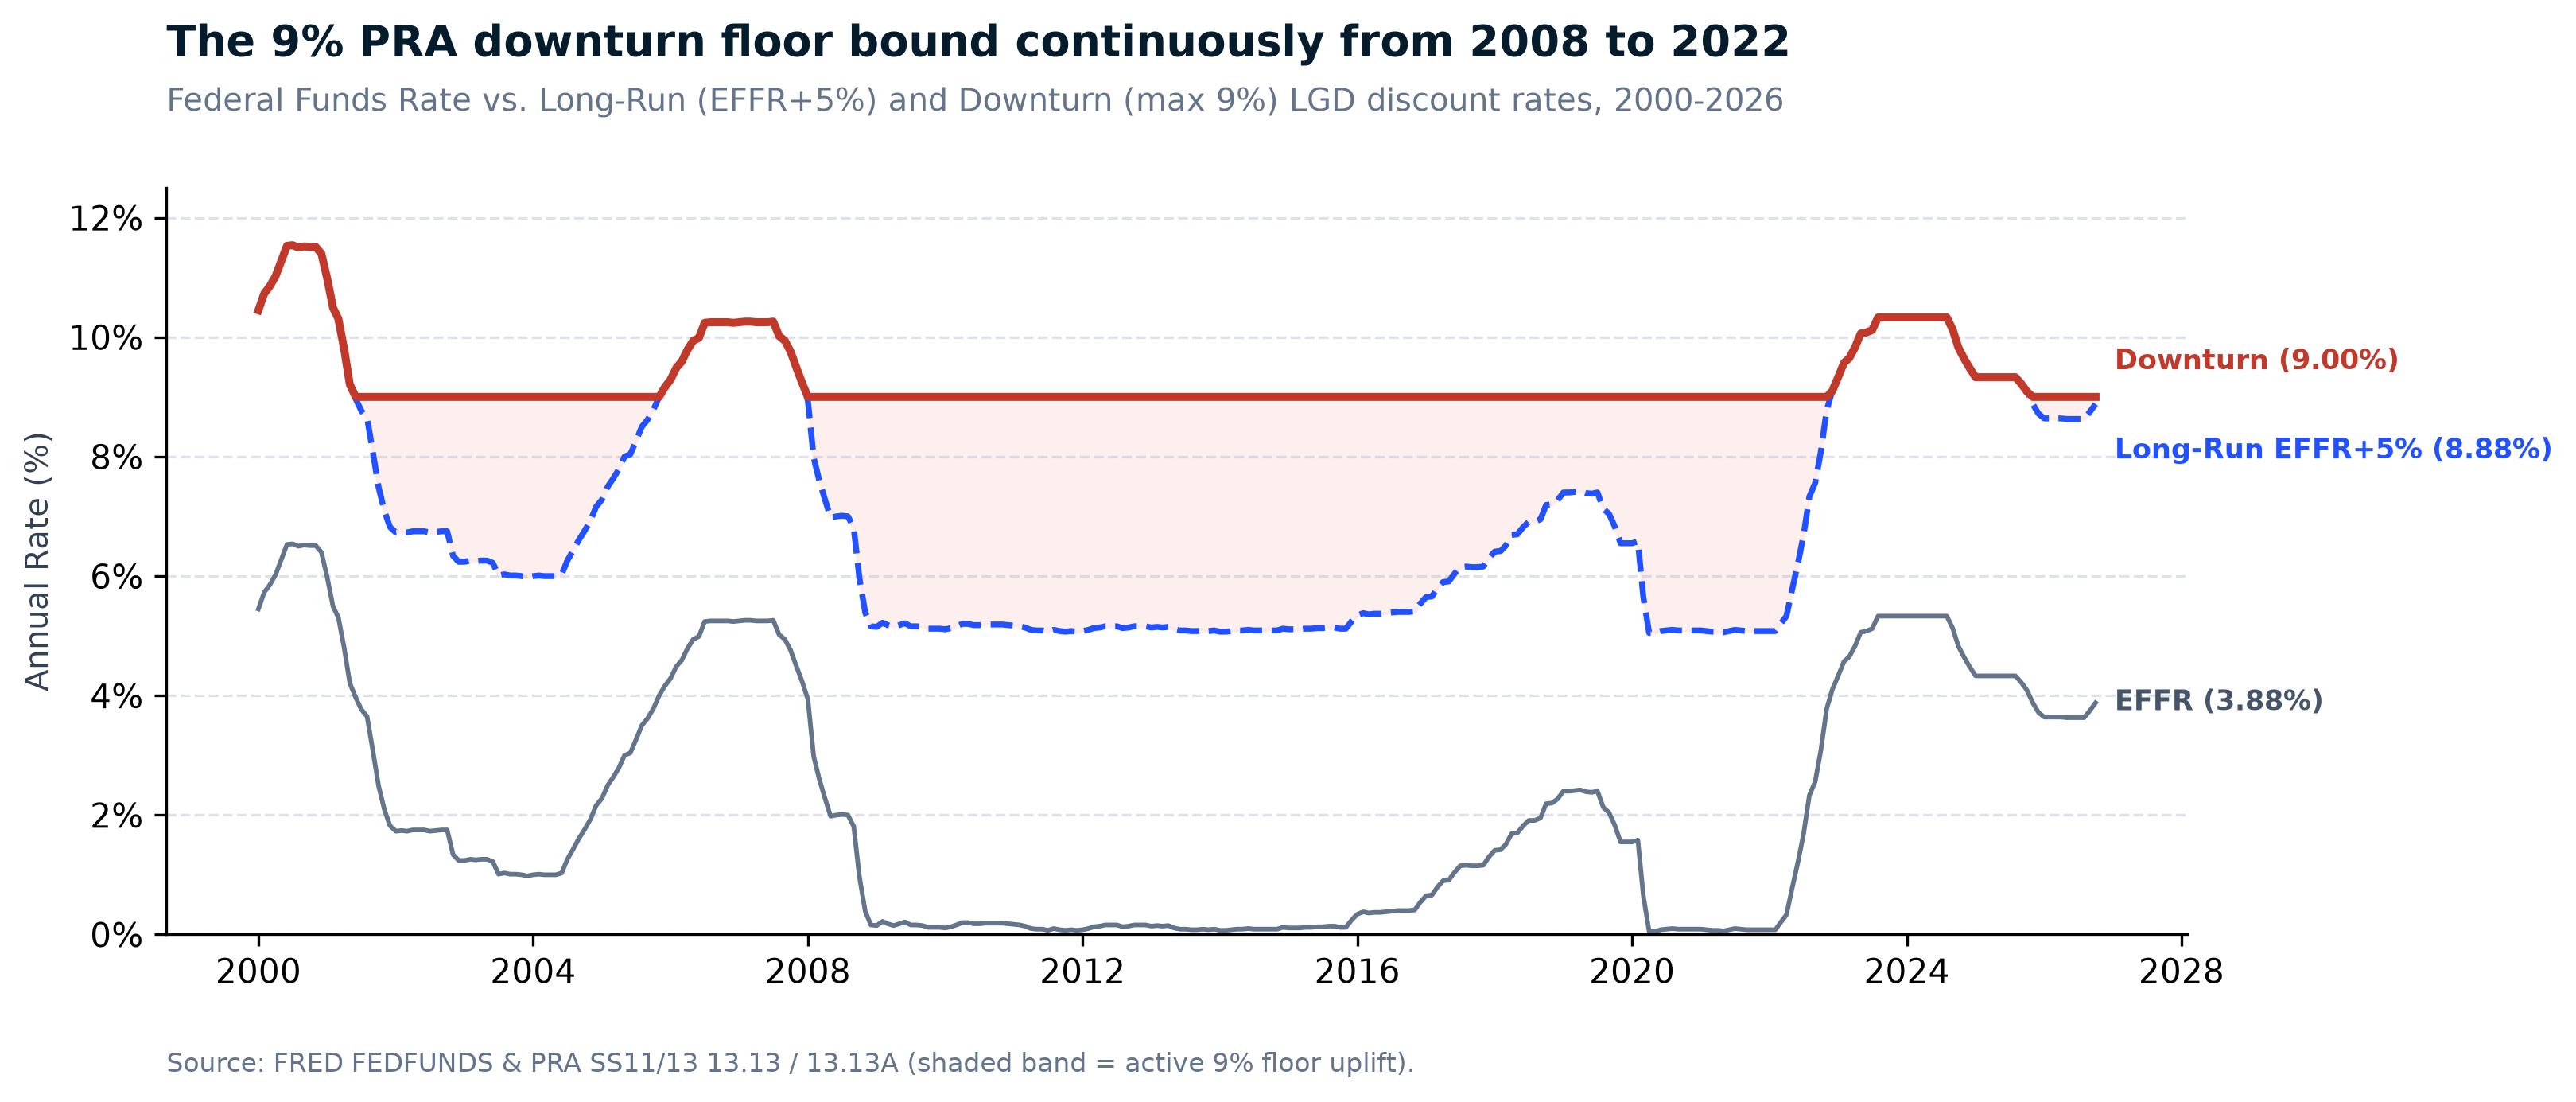

In [4]:
# Fetch the complete 2000-2026 monthly discount rate history from in-memory macro_economic_mart
# Query period, EFFR, long-run discount rate, and downturn discount rate ordered chronologically
plot_df = con.execute("""
    SELECT period, federal_funds_rate_pct, lgd_discount_rate_long_run_pct, lgd_discount_rate_downturn_pct
    FROM macro_economic_mart
    ORDER BY period
""").fetchdf()

# Render a McKinsey-style rate-regime chart showing where the 9% PRA downturn floor binds
# Plot EFFR, long-run (EFFR+5%), and downturn (max(9%, EFFR+5%)) with shaded floor gaps at 300 dpi
fig, ax = plt.subplots(figsize=(11.0, 4.6), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
ax.plot(plot_df["period"], plot_df["lgd_discount_rate_downturn_pct"], color="#C0392B", linewidth=2.4, zorder=4)
ax.plot(plot_df["period"], plot_df["lgd_discount_rate_long_run_pct"], color="#2251FF", linewidth=1.8, linestyle="--", zorder=3)
ax.plot(plot_df["period"], plot_df["federal_funds_rate_pct"], color="#64748B", linewidth=1.4, zorder=2)
ax.fill_between(plot_df["period"], plot_df["lgd_discount_rate_long_run_pct"], plot_df["lgd_discount_rate_downturn_pct"], color="#FEE2E2", alpha=0.55, zorder=1)

last_dt = plot_df["period"].iloc[-1]
ax.text(last_dt, plot_df["lgd_discount_rate_downturn_pct"].iloc[-1] + 0.35, f"  Downturn ({plot_df['lgd_discount_rate_downturn_pct'].iloc[-1]:.2f}%)", va="bottom", fontsize=8.5, fontweight="bold", color="#C0392B")
ax.text(last_dt, plot_df["lgd_discount_rate_long_run_pct"].iloc[-1] - 0.55, f"  Long-Run EFFR+5% ({plot_df['lgd_discount_rate_long_run_pct'].iloc[-1]:.2f}%)", va="top", fontsize=8.5, fontweight="bold", color="#2251FF")
ax.text(last_dt, plot_df["federal_funds_rate_pct"].iloc[-1], f"  EFFR ({plot_df['federal_funds_rate_pct'].iloc[-1]:.2f}%)", va="center", fontsize=8.5, fontweight="bold", color="#475569")

ax.set_ylim(0, 12.5)
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Annual Rate (%)", fontsize=9.5, color="#334155")
fig.text(0.07, 0.94, "The 9% PRA downturn floor bound continuously from 2008 to 2022", fontsize=13, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.89, "Federal Funds Rate vs. Long-Run (EFFR+5%) and Downturn (max 9%) LGD discount rates, 2000-2026", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: FRED FEDFUNDS & PRA SS11/13 13.13 / 13.13A (shaded band = active 9% floor uplift).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.84, top=0.82, bottom=0.14)
plt.show()

# Close the in-memory DuckDB connection cleanly
# Release temporary in-memory tables
con.close()

The shaded red band highlights every month where the **9% downturn floor** lifts the discount rate above `EFFR + 5%`—crucial when discounting post-default recoveries in Module 04 (`LGD`). Next, `04_build_sample_db.py` creates the self-contained `0.03%` sample database used across development and these walkthrough notebooks.